In [1]:
from google.colab import files
uploaded = files.upload()
# A "Choose files" button appears. Select the CSV.

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)   # (7043, 21)  -> 7043 customers, 21 columns
df.head()         # shows the first 5 rows

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()                    # column names, types, non-null counts
df["Churn"].value_counts()   # No: 5174, Yes: 1869

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count
Churn,
No,5174
Yes,1869


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()   # 11  -> 11 blank rows became NaN

np.int64(11)

In [5]:
df = df.dropna()
df.shape   # (7032, 21)

(7032, 21)

In [6]:
df = df.drop("customerID", axis=1)
df.shape   # (7032, 20)

(7032, 20)

In [7]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["Churn"].value_counts()   # 0: 5163, 1: 1869

,count
Churn,
0,5163
1,1869


In [8]:
df.duplicated().sum()   # a small number is normal here; leave it

np.int64(22)

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")   # cleaner chart background

In [10]:
churn_rate = df["Churn"].mean() * 100
print(f"Churn rate: {churn_rate:.1f}%")   # Churn rate: 26.6%

Churn rate: 26.6%


In [11]:
df.groupby("Contract")["Churn"].mean() * 100
# Month-to-month    ~42.7
# One year          ~11.3
# Two year          ~2.8

,Churn
Contract,
Month-to-month,42.709677
One year,11.277174
Two year,2.848665


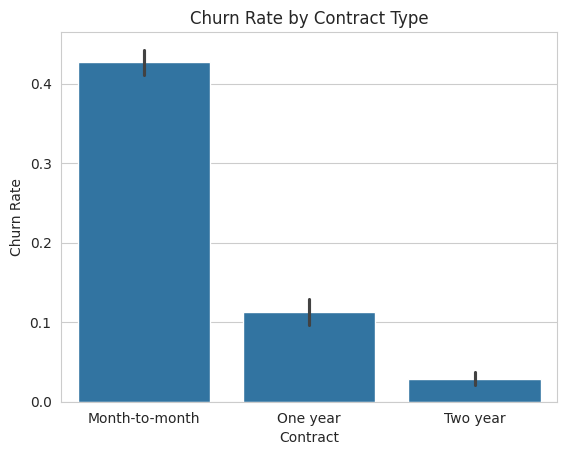

In [12]:
sns.barplot(x="Contract", y="Churn", data=df)
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.show()

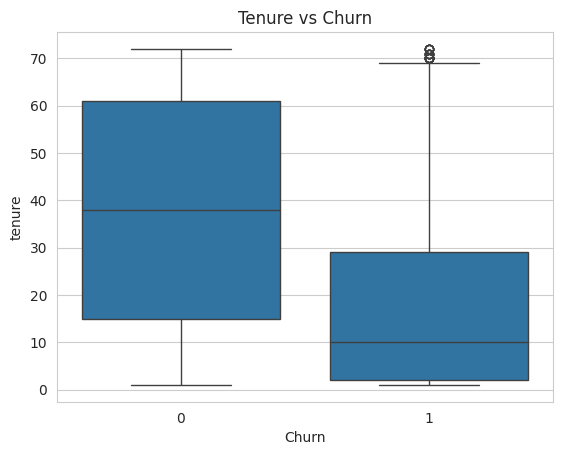

In [13]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

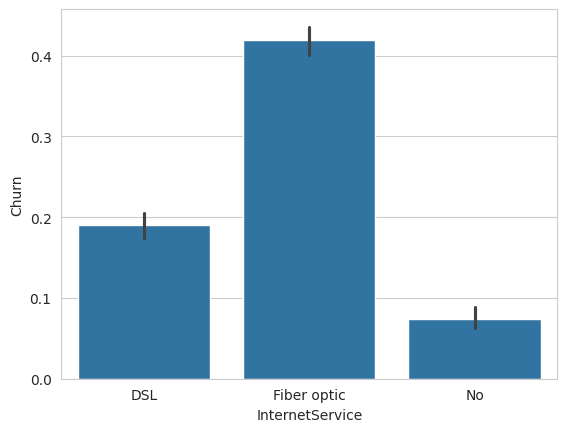

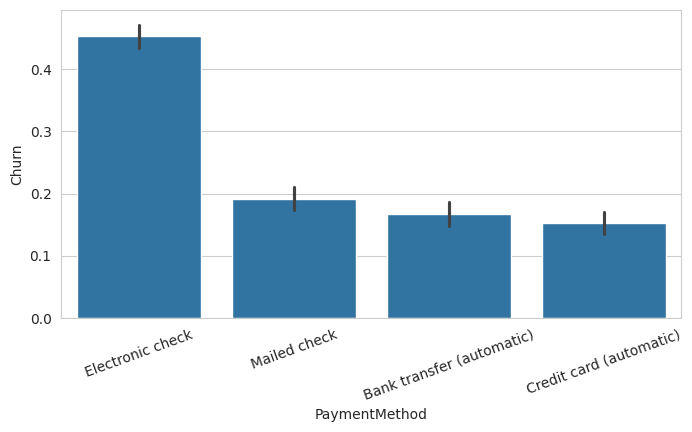

In [14]:
sns.barplot(x="InternetService", y="Churn", data=df)
plt.show()

plt.figure(figsize=(8, 4))
sns.barplot(x="PaymentMethod", y="Churn", data=df)
plt.xticks(rotation=20)
plt.show()

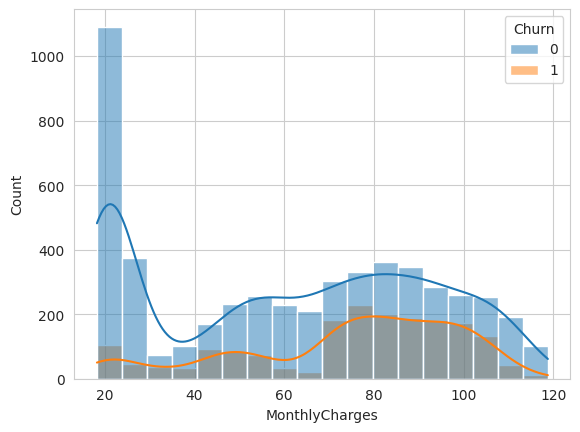

In [15]:
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", kde=True)
plt.show()

In [16]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoded.shape   # (7032, 31)  -> 30 feature columns + Churn
df_encoded.head()  # all values are numbers now

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [17]:
X = df_encoded.drop("Churn", axis=1)   # what the model learns from
y = df_encoded["Churn"]                # what it predicts

print(X.shape)   # (7032, 30)
print(y.shape)   # (7032,)

(7032, 30)
(7032,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)   # (5625, 30)
print(X_test.shape)    # (1407, 30)
print(y_train.mean())  # ~0.266  -> churn rate in train
print(y_test.mean())   # ~0.266  -> same churn rate in test

(5625, 30)
(1407, 30)
0.2657777777777778
0.2658137882018479


In [19]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled[num_cols].describe()   # mean ≈ 0, std ≈ 1

,tenure,MonthlyCharges,TotalCharges
count,5.625000e+03,5.625000e+03,5.625000e+03
mean,-1.291609e-16,3.157968e-17,8.842310e-18
std,1.000089e+00,1.000089e+00,1.000089e+00
min,-1.286145e+00,-1.547843e+00,-1.003365e+00
25%,-9.601500e-01,-9.698847e-01,-8.301191e-01
50%,-1.451620e-01,1.860324e-01,-3.918414e-01
75%,9.550717e-01,8.320837e-01,6.591681e-01
max,1.607062e+00,1.782062e+00,2.805224e+00


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, lr_pred))   # ~0.80
print(classification_report(y_test, lr_pred))

Accuracy: 0.8045486851457001
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [21]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))   # ~0.78-0.79
print(classification_report(y_test, rf_pred))

Accuracy: 0.7867803837953091
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [22]:
lr2 = LogisticRegression(max_iter=1000, class_weight="balanced")
lr2.fit(X_train_scaled, y_train)

lr2_pred = lr2.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, lr2_pred))
print(classification_report(y_test, lr2_pred))

Accuracy: 0.7256574271499645
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



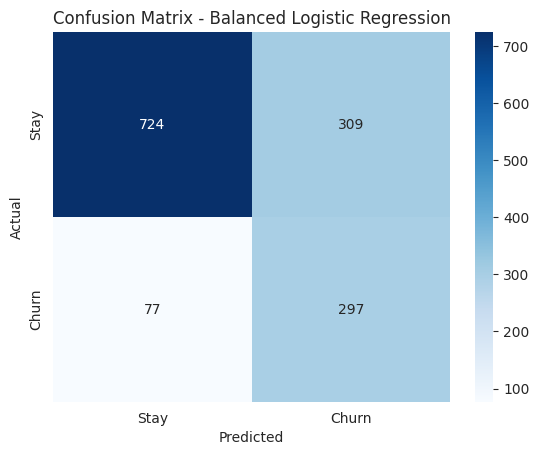

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr2_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.show()
# roughly: [[~723, ~310], [~79, ~295]]

Contract_Two year   -1.456973
tenure              -1.253034
Contract_One year   -0.788478
MonthlyCharges      -0.485947
PhoneService_Yes    -0.373091
dtype: float64
StreamingMovies_Yes               0.371653
StreamingTV_Yes                   0.386970
PaymentMethod_Electronic check    0.411009
TotalCharges                      0.606596
InternetService_Fiber optic       1.134813
dtype: float64


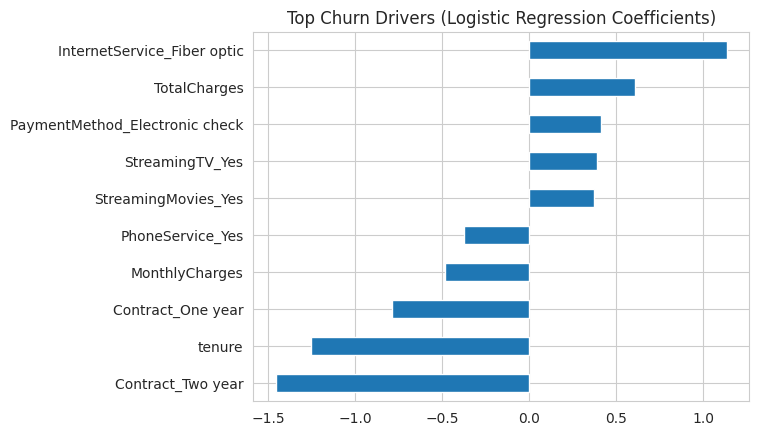

In [24]:
coefs = pd.Series(lr2.coef_[0], index=X.columns).sort_values()

# Strongest reasons customers STAY (negative)
print(coefs.head(5))
# Strongest reasons customers LEAVE (positive)
print(coefs.tail(5))

pd.concat([coefs.head(5), coefs.tail(5)]).plot(kind="barh")
plt.title("Top Churn Drivers (Logistic Regression Coefficients)")
plt.show()

In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Logistic Regression (balanced)": lr2_pred,
}

rows = []
for name, pred in models.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

pd.DataFrame(rows).round(2)
# a clean 3-row table with all four metrics

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.80,0.65,0.57,0.61
1,Random Forest,0.79,0.62,0.51,0.56
2,Logistic Regression (balanced),0.73,0.49,0.79,0.61


## Conclusion
- Overall churn rate is 26.6%.
- Month-to-month contracts, fiber optic internet, electronic check payment and short tenure are the strongest churn signals.
- The balanced Logistic Regression catches 79% of churners (recall) at 49% precision.
- Recommendations: offer discounts for 1-2 year contracts, investigate fiber optic service quality, and run retention offers in the first months of a customer's tenure.